In [1]:
import gc
import re

In [2]:
import textwrap

import matplotlib
import numpy as np
import xarray as xr
from matplotlib import colors as mcol
from matplotlib import pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [3]:
from data import (
    _load_pressure_dataset,
    _load_single_dataset,
    ds_pressure,
    ds_single,
)

In [4]:
from pathlib import Path

plots = Path("plots")

In [5]:
tab10 = matplotlib.colormaps["tab10"].colors

In [6]:
from compression_recommendations import Recommendations
from compression_recommendations.requirements.error_bounds.max import (
    MaxPointwiseAbsoluteErrorBoundRequirement,
    MaxPointwiseQuadraticErrorBoundRequirement,
    MaxPointwiseRelativeErrorBoundRequirement,
)

In [7]:
expert_recommendations = Recommendations.provide

In [8]:
with Path("recommendations", "ensemble-spread.yaml").open("r") as f:
    ensemble_recommendations = Recommendations.load(f)

In [9]:
def plot_ensemble_mean_spread(
    mean: xr.DataArray,
    spread: xr.DataArray,
    plot: Path,
    extra_markers: dict,
    title_extra: str = "",
):
    mean, spread = mean.copy(deep=True), spread.copy(deep=True)
    meanv, spreadv = mean.values.flatten(), spread.values.flatten()

    fig, ax = plt.subplots(num=1, clear=True)

    m0, m01, m999, m100 = np.nanquantile(meanv, [0.0, 0.001, 0.999, 1.0])
    s99, s100 = np.nanquantile(spreadv, [0.99, 1.0])

    if m01 != m999:
        ms = m999 - m01
        xl, xh = m01 - ms * 0.05, m999 + ms * 0.05
        if xl < 0 and xh > 0 and xl * 2 < -xh and xh * 2 > -xl:
            xl = -max(-xl, xh)
            xh = -xl
        ax.set_xlim(xl, xh)
    elif m100 != m0:
        ms = m100 - m0
        xl, xh = m0 - ms * 0.05, m100 + ms * 0.05
        if xl < 0 and xh > 0 and xl * 2 < -xh and xh * 2 > -xl:
            xl = -max(-xl, xh)
            xh = -xl
        ax.set_xlim(xl, xh)
    else:
        ax.set_xlim(-0.05, 0.05)
    # xl, xh = m0, m100
    # if xl < 0 and xh > 0 and xl * 2 < -xh and xh * 2 > -xl:
    #     xl = -max(-xl, xh)
    #     xh = -xl
    # ax.set_xlim(xl, xh)
    if s99 != 0.0:
        ss = s99
        ax.set_ylim(0.0 - ss * 0.05, s99 + ss * 0.05)
    elif s100 != 0.0:
        ss = s100
        ax.set_ylim(0.0 - ss * 0.05, s100 + ss * 0.05)
    else:
        ax.set_ylim(-0.05, 0.05)

    ax.set_title(
        "\n".join(
            textwrap.wrap(f"{mean.long_name} ({mean.name}){title_extra}", width=45)
        )
    )

    spread_units = re.sub(r"\*\*(-?\d+)", r"$^{\1}$", spread.units)
    ax.set_ylabel(f"spread [{spread_units}]")

    ax.hist2d(
        meanv,
        spreadv,
        bins=[51, 51],
        range=[ax.get_xlim(), ax.get_ylim()],
        cmap="GnBu",
        norm=mcol.LogNorm(),
    )

    bound_legend = []

    for p, pp, ls in zip(
        ["100.0%", "99.9%", "99.0%", "95.0%"],
        ["0%", "0.1%", "1%", "5%"],
        ["-", "-.", "--", ":"],
    ):
        (ensemble_requirement,) = ensemble_recommendations.search(
            markers={
                "cf-short-name": mean.name,
                "tags": f"pick,{p}",
                **extra_markers,
            }
        )

        if isinstance(ensemble_requirement, MaxPointwiseAbsoluteErrorBoundRequirement):
            ax.axhline(
                ensemble_requirement.value,
                c="white",
                lw=3,
            )
            bound_legend.append(
                ax.axhline(
                    ensemble_requirement.value,
                    ls=ls,
                    c=tab10[0],
                    lw=2,
                    zorder=2.5,
                    label=rf"{pp}: $\epsilon_{{abs}}$ = {ensemble_requirement.value:.2}",
                )
            )
        elif isinstance(
            ensemble_requirement, MaxPointwiseRelativeErrorBoundRequirement
        ):
            x = ax.get_xlim()
            x = np.array(sorted(list(x) + [0.0]))
            ax.plot(
                x,
                np.abs(x) * ensemble_requirement.value,
                c="white",
                lw=3,
            )
            bound_legend.append(
                ax.plot(
                    x,
                    np.abs(x) * ensemble_requirement.value,
                    ls=ls,
                    c=tab10[1],
                    lw=2,
                    zorder=2.5,
                    label=rf"{pp}: $\epsilon_{{rel}}$ = {ensemble_requirement.value:.2%}",
                )[0]
            )
        elif isinstance(
            ensemble_requirement, MaxPointwiseQuadraticErrorBoundRequirement
        ):
            x = ax.get_xlim()
            x = np.linspace(x[0], x[1], num=100)
            q, mi, ma = (
                ensemble_requirement.value,
                ensemble_requirement.minimum,
                ensemble_requirement.maximum,
            )
            ax.plot(
                x,
                q - q * (-1.0 + 2.0 * (x - mi) / (ma - mi)) ** 2,
                c="white",
                lw=3,
            )
            bound_legend.append(
                ax.plot(
                    x,
                    q - q * (-1.0 + 2.0 * (x - mi) / (ma - mi)) ** 2,
                    ls=ls,
                    c=tab10[2],
                    lw=2,
                    zorder=2.5,
                    label=rf"{pp}: $\epsilon_{{qua}}$ = {q:.2}",
                )[0]
            )
        else:
            assert False, repr(ensemble_requirement)

    # ax.axhline(
    #     info["lpabsolute"].iloc[0],
    #     c="white",
    #     lw=3,
    # )
    # bound_legend.append(
    #     ax.axhline(
    #         info["lpabsolute"].iloc[0],
    #         ls=":",
    #         c="black",
    #         lw=2,
    #         zorder=2.5,
    #         label=f"linear packing: B={info['lpbits'].iloc[0]}",
    #     )
    # )

    ax.xaxis.set_major_locator(plt.MaxNLocator(7))

    ax.legend(handles=bound_legend, loc="upper right", title="Ensemble Bounds")

    divider = make_axes_locatable(ax)

    ax_histx = divider.append_axes("bottom", 0.33, pad=0.15, sharex=ax)
    ax_histx.hist(meanv, bins=51, log=True)
    ax_histx.invert_yaxis()
    mean_units = re.sub(r"\*\*(-?\d+)", r"$^{\1}$", mean.units)
    ax_histx.set_xlabel(f"mean [{mean_units}]")
    ax.xaxis.set_tick_params(which="both", labelbottom=False)

    ax_histy = divider.append_axes("right", 0.33, pad=0.15, sharey=ax)
    ax_histy.hist(spreadv, bins=51, log=True, orientation="horizontal")
    ax_histy.tick_params(axis="x", labelrotation=45)
    ax_histy.yaxis.set_tick_params(which="both", labelleft=False)

    plt.tight_layout()

    plot.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(plot)

    plt.close(fig)

In [10]:
from tqdm import tqdm

In [11]:
for i, key in tqdm(enumerate(["hcc"])):  # tqdm(enumerate(sorted(ds_single.mean))):
    if (i > 0) and (i % 50 == 0):
        del ds_single
        gc.collect()
        ds_single = _load_single_dataset()
    plot_ensemble_mean_spread(
        ds_single.mean[key],
        ds_single.spread[key],
        plots / "single" / f"{key}.png",
        extra_markers={"level-kind": "single"},
    )

1it [00:11, 11.12s/it]


In [12]:
for i, key in tqdm(
    enumerate(["vo", "z", "r", "u"])
):  # tqdm(enumerate(sorted(ds_pressure.mean))):
    if (i > 0) and (i % 8 == 0):
        del ds_pressure
        gc.collect()
        ds_pressure = _load_pressure_dataset()
    for pressure in (
        [850.0] if key in ["vo", "z", "u"] else [50.0, 500.0]
    ):  # sorted(ds_pressure.mean[key].pressure_level.values):
        plot_ensemble_mean_spread(
            ds_pressure.mean[key].sel(pressure_level=pressure),
            ds_pressure.spread[key].sel(pressure_level=pressure),
            plots / "pressure" / f"{key}-{pressure}hPa.png",
            extra_markers={"level-kind": "pressure", "level-value": pressure},
            title_extra=f" at {pressure}hPa",
        )

4it [00:55, 13.88s/it]


In [13]:
from IPython.display import Image, display

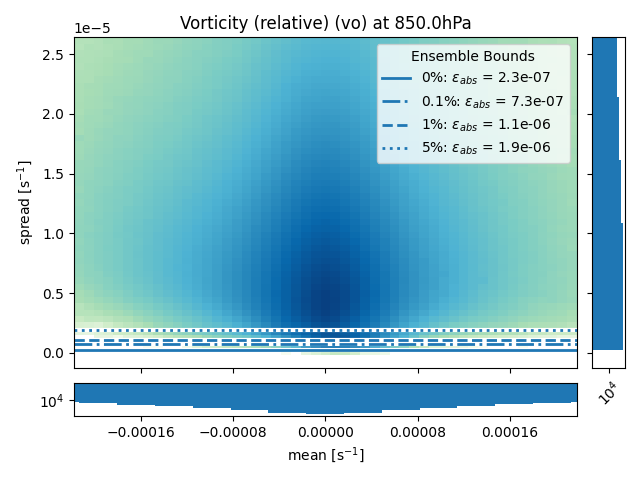

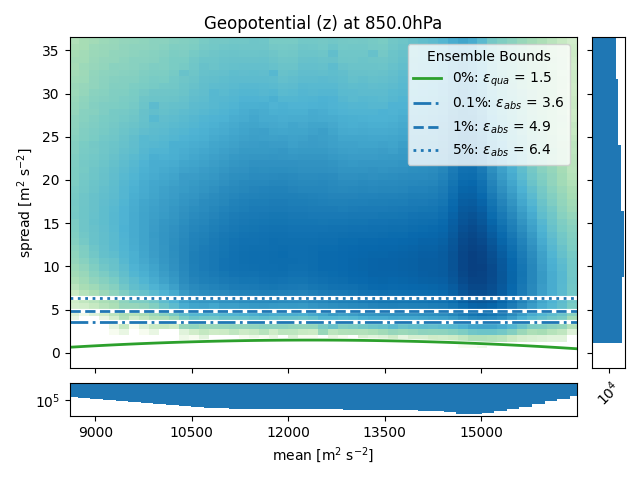

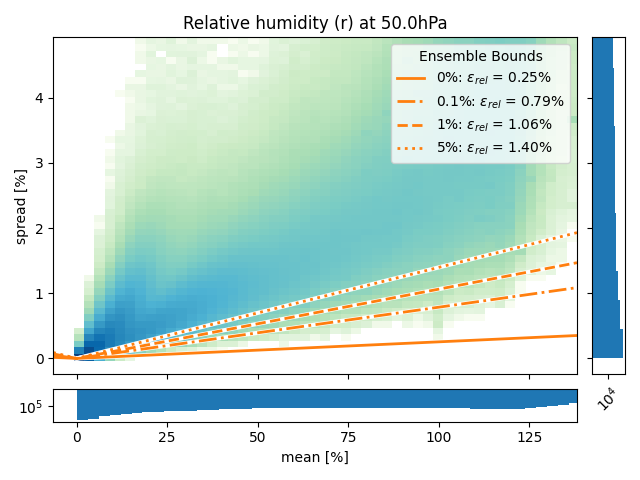

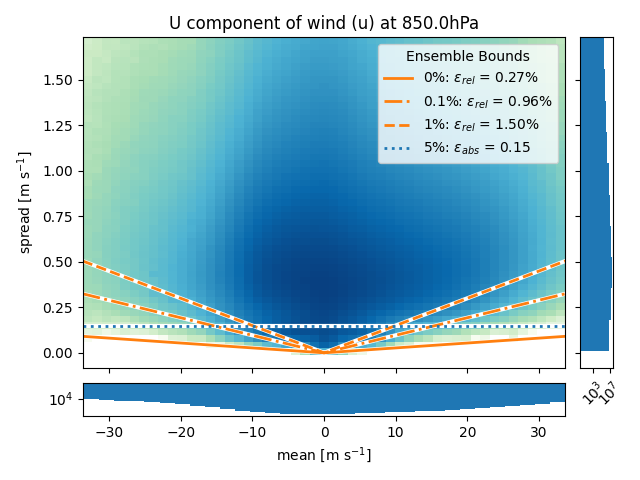

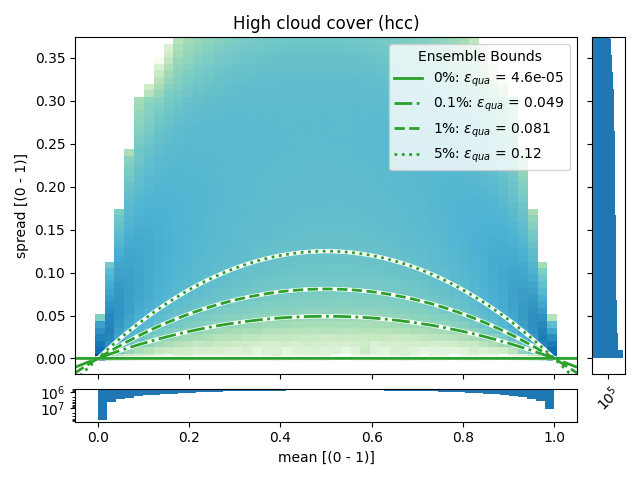

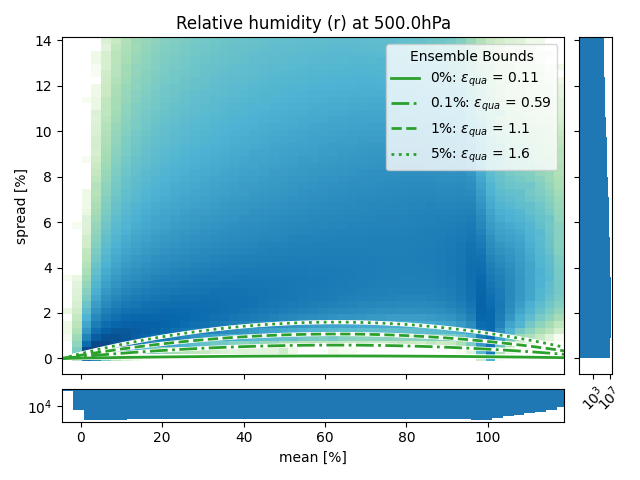

In [14]:
display(Image(plots / "pressure" / "vo-850.0hPa.png"))
display(Image(plots / "pressure" / "z-850.0hPa.png"))
display(Image(plots / "pressure" / "r-50.0hPa.png"))
display(Image(plots / "pressure" / "u-850.0hPa.png"))
display(Image(plots / "single" / "hcc.png"))
display(Image(plots / "pressure" / "r-500.0hPa.png"))